<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

HW #7

November 16, 2026

# Introduction

The following is an analysis of a wine dataset to perform unsupervised classification based on its features. This notebook uses methods and documentation from two notebooks: (1) [plant_classification.ipynb](https://github.com/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb) for PCA Analysis and (2) [customer_segmentation.ipynb](https://github.com/bforoura/ML26/blob/main/Module8_Unsupervised/customer_segmentation.ipynb) for the documentation and methods for performing each task below. The wine dataset contains 13 features which will be condensed into 2 principal components.

This notebook uses code and methods from the class End-to-End Machine Learning Project and makes reference to our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)) as well as the Module 8 overview.

# **Task 1: Setup, Data Loading, and Exploratory Data Analysis**

Instructions: **Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.**

We can see that all features are float values. Using the `.info()` method, we can see that all features have values. The wine data set has three classes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

# Load the wine dataset as a pandas DataFrame for ease of analysis
df = load_wine(as_frame=True)
X = df.data
y = df.target

# Display basic dataset dimensions and class distribution
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", df.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())


X.info()

Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue       

Taking a distribution of features, we can see that a standard distribution does not change the shape of most features. But after standardization, each feature has a similar range.

array([[<Axes: title={'center': 'alcohol'}>,
        <Axes: title={'center': 'malic_acid'}>,
        <Axes: title={'center': 'ash'}>,
        <Axes: title={'center': 'alcalinity_of_ash'}>],
       [<Axes: title={'center': 'magnesium'}>,
        <Axes: title={'center': 'total_phenols'}>,
        <Axes: title={'center': 'flavanoids'}>,
        <Axes: title={'center': 'nonflavanoid_phenols'}>],
       [<Axes: title={'center': 'proanthocyanins'}>,
        <Axes: title={'center': 'color_intensity'}>,
        <Axes: title={'center': 'hue'}>,
        <Axes: title={'center': 'od280/od315_of_diluted_wines'}>],
       [<Axes: title={'center': 'proline'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

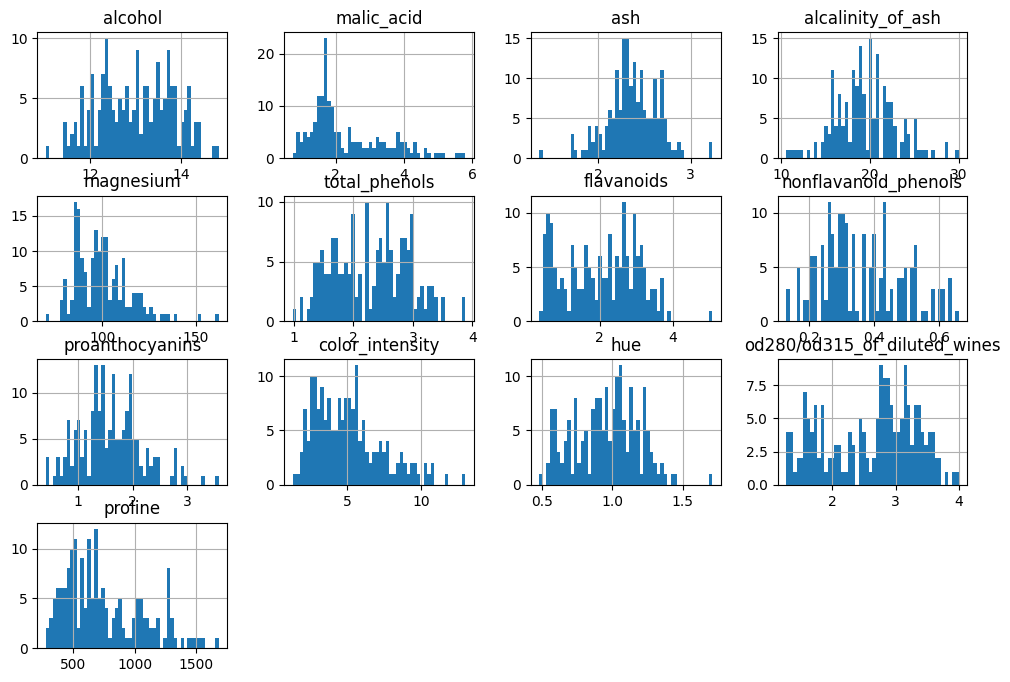

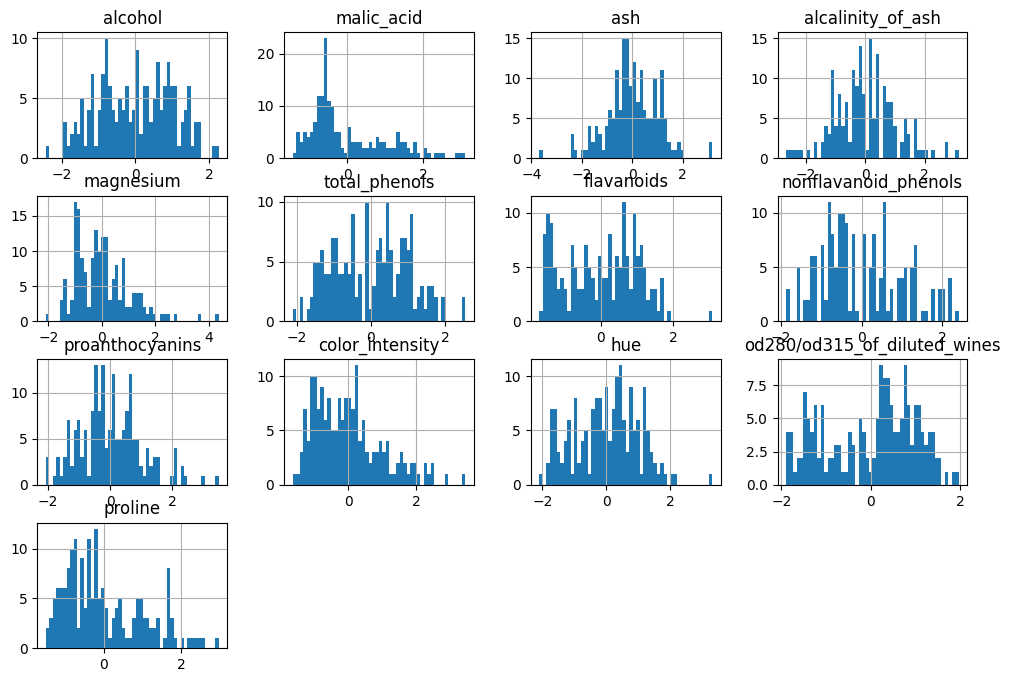

In [2]:
from sklearn.preprocessing import StandardScaler
X.hist(bins=50, figsize=(12, 8))

# Feature scaling (essential for K-Means distance metrics)
scaler = StandardScaler()
X_scaled_copy = scaler.fit_transform(X)

df_scaled_copy = pd.DataFrame(X_scaled_copy, columns=scaler.get_feature_names_out())

df_scaled_copy.hist(bins=50, figsize=(12,8))

# **Task 2**

**Instruction: Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side:**

- **The Elbow Method curve**

- **The Silhouette Scores curve for k in [2, 10]. Print the optimal k value suggested by both metrics.**

The following plots an Elbow Method curve and Silhouette curve to identify which k values are optimal for an unsupervised clustering analysis.

According to pages 244 and 248 of our textbook, the Elbow Method curve plots inertia (the mean squared error of distances from points) against values of k. Inertia decreases with greater values of k. However, we would want to find values of k where inertia has slowed but groupings still retain meaning. This represents the center of the Elbow Method curve where the curve begins to flatten. The Silhouette score plots the ratio of distance between points to their cluster and points to the nearest cluster with varying values of k. We would want to pick a value for k that has a higher silhouette score, closer to 1.

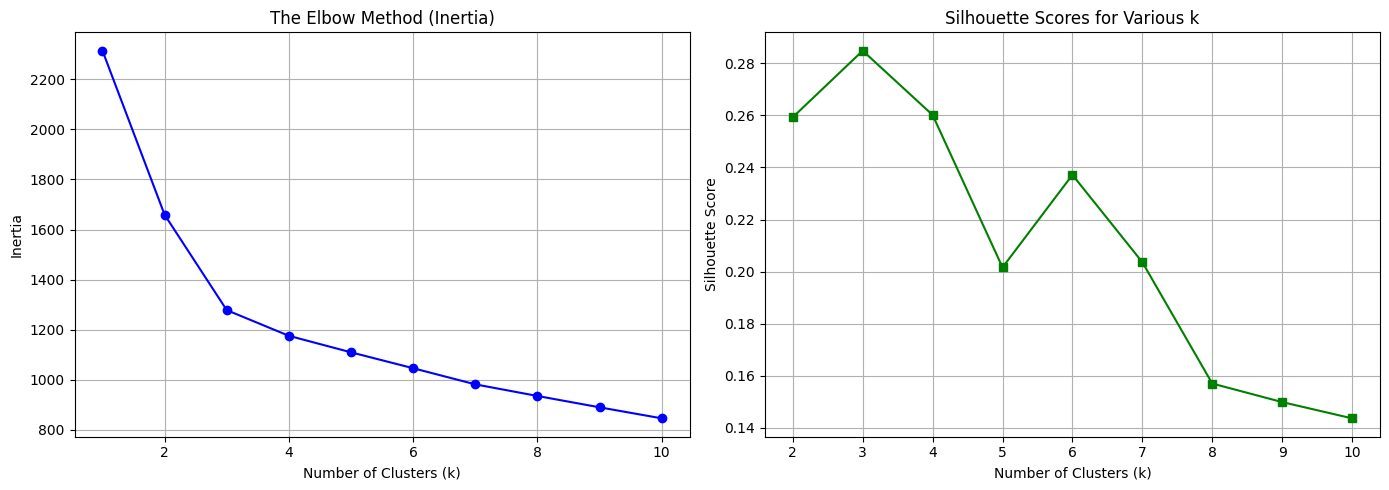

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Feature scaling (essential for K-Means distance metrics)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#list for storing inertia values
inertia = []
#list for storing silhouette scores
silhouette_scores = []
#defines the range of k values
K_range = range(2, 11)

# Calculate inertia for k from 1 to 10
for k in range(1, 11):
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)

# Calculate silhouette score for k from 2 to 10
for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plotting Elbow Method and Silhouette Scores side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method Plot
ax1.plot(range(1, 11), inertia, marker='o', color='b', linestyle='-')
ax1.set_title('The Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)

# Silhouette Score Plot
ax2.plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
ax2.set_title('Silhouette Scores for Various k')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

Both the elbow method and the silhouette score reveal that 3 is the ideal number of clusters. When k=3, the elbow method curve begins to flatten, and the silhouette score is highest.

# Task 3

Instructions: **Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the Voronoi method.**

Here, we will use a principal component analysis to condense the 13-feature space into 2 principal components. We will cluster points along these two principal components using the Voronoi method. This method plots the space around points to visualize which points belong to which cluster. The space is plotted so that points closest to each centroid and farther from the others are plotted in the same space.

Cluster Centers (Original Scale - Annual Income, Spending Score):
[[-200.12078121   -4.65496555]
 [ 415.44327503   -5.65691996]
 [  40.52709984   22.15562934]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


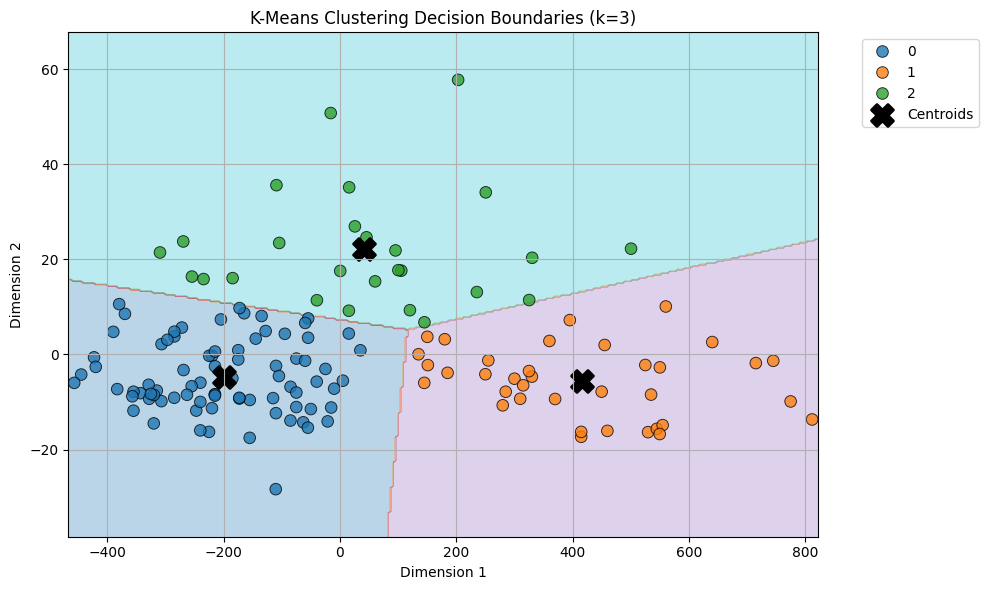

In [4]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import seaborn as sns

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit PCA on training data only to avoid data leakage
pca_clf = PCA(n_components=2)
# Forming training and test sets from the PCA transformation
X_train_reduced = pca_clf.fit_transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

#Creating a new dataframe representing the dimensionality reduction
df = pd.DataFrame(X_train_reduced, columns=["Dimension 1", "Dimension 2"])

# Feature scaling (essential for K-Means distance metrics)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Instantiate and fit K-Means with k=3
k = 3
# Creating a KMeans instance.
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#Generate predicted clusters
y_pred = kmeans.fit_predict(X_scaled)

# Add cluster labels to the dataframe
df['Cluster'] = y_pred

# Extract cluster centers and inverse transform back to original scale
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

print("Cluster Centers (Original Scale - Annual Income, Spending Score):")
print(centroids)

# Plotting decision boundaries, data points, and centroids
plt.figure(figsize=(10, 6))

# Create a mesh grid to plot decision boundaries (Voronoi regions)
x_min, x_max = X_train_reduced[:, 0].min() - 10, X_train_reduced[:, 0].max() + 10
y_min, y_max = X_train_reduced[:, 1].min() - 10, X_train_reduced[:, 1].max() + 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Predict cluster for each point in the mesh grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_points_scaled = scaler.transform(grid_points)
Z = kmeans.predict(grid_points_scaled)
Z = Z.reshape(xx.shape)

# Plot the decision boundaries using contour regions
plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

# Plot the customer data points colored by their assigned cluster
sns.scatterplot(
    x='Dimension 1',
    y='Dimension 2',
    hue='Cluster',
    data=df,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

# Plot the centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    linewidths=2,
    color='black',
    label='Centroids'
)

plt.title('K-Means Clustering Decision Boundaries (k=3)')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

We can see that points are labeled across the space of each principal component and according to their proximity to each cluster. We can see that every point is assigned to a cluster.

# Task 4: Heatmap

Instructions: **Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.**

We can use a sample of the data set with the following method, `df.sample()` and [reference](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.sample.html) to generate a sample of points to plot. The purpose is to show how soft clustering eventually corresponds to each cluster assignment.

In [5]:
sample = df.sample(5, random_state=50)
sample

,Dimension 1,Dimension 2,Cluster
87,560.394046,10.094732,1
12,-94.829181,4.351464,0
103,395.306144,7.233875,1
34,203.214753,57.754282,2
25,-307.108384,-9.817300,0


Now that we have this sample, we can plot each point's distance using the Heatmap below.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


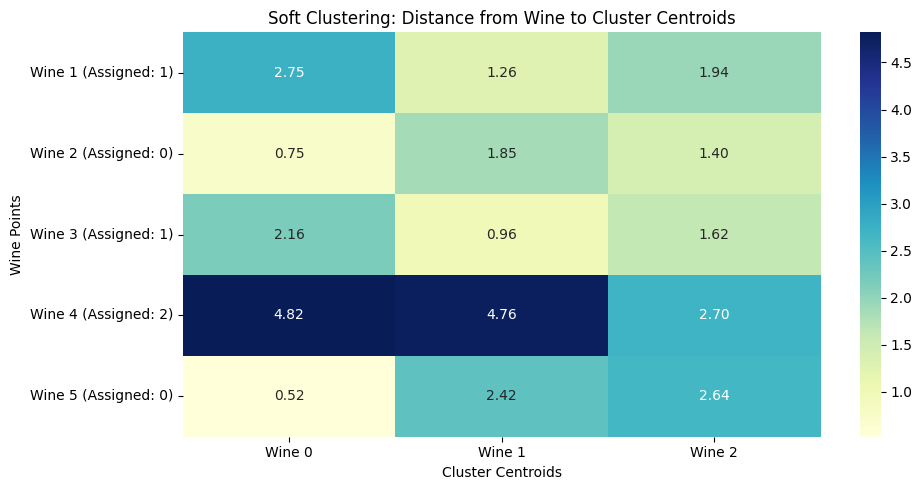

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define new customer points (Annual Income, Spending Score)
X_new = np.array([
  [560.394046,	10.094732],	# Category 1
  [-94.829181,	4.351464], # Category 0
  [395.306144,	7.233875], # Category 1
  [203.214753,	57.754282],	# Category 2
  [-307.108384,	-9.817300] # Category 0
])

# Scale the new points using the fitted scaler
X_new_scaled = scaler.transform(X_new)

# Compute distances from each new point to all k centroids
distances = kmeans.transform(X_new_scaled)

# Hard clustering prediction for these new points
new_predictions = kmeans.predict(X_new_scaled)

# Visualize distances using a heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    distances,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"Wine {i}" for i in range(k)],
    yticklabels=[f"Wine {i+1} (Assigned: {pred})" for i, pred in enumerate(new_predictions)]
)
plt.title("Soft Clustering: Distance from Wine to Cluster Centroids")
plt.xlabel("Cluster Centroids")
plt.ylabel("Wine Points")
plt.tight_layout()
plt.show()

Predictably, we see that points with distances closest to each cluster's centroid are assigned to that cluster.

# Task 5:

Instructions: **Fit a DBSCAN model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.**

Here, we will plot several DBSCAN models, changing hyperparameters of epsilon and minimum samples. Epsilon is the distance between points to form a cluster and minimum samples determines which samples fall within each cluster.

When values of epsilon or miminum samples are small, we see more clusters. We see less clusters when these values are greater. Importantly, a DBSCAN model excludes points from any cluster. An important goal in evaluating the optimal DBSCAN is to see which model defines an appropriate number of clusters and describes most points in the dataset.

For instance, when epsilon is equal to 0.35 and minimum samples is equal to 6, we get closest to defining the three clusters in the wine dataset which is similar to the Voronoi plot. However, we see that a number of points are not clustered.

Estimated number of clusters: 15
Estimated number of noise points: 25
Estimated number of clusters: 10
Estimated number of noise points: 11
Estimated number of clusters: 4
Estimated number of noise points: 54
Estimated number of clusters: 4
Estimated number of noise points: 30
Estimated number of clusters: 4
Estimated number of noise points: 19
Estimated number of clusters: 1
Estimated number of noise points: 12
Estimated number of clusters: 3
Estimated number of noise points: 85
Estimated number of clusters: 3
Estimated number of noise points: 42
Estimated number of clusters: 3
Estimated number of noise points: 28
Estimated number of clusters: 2
Estimated number of noise points: 22
Estimated number of clusters: 1
Estimated number of noise points: 107
Estimated number of clusters: 2
Estimated number of noise points: 56


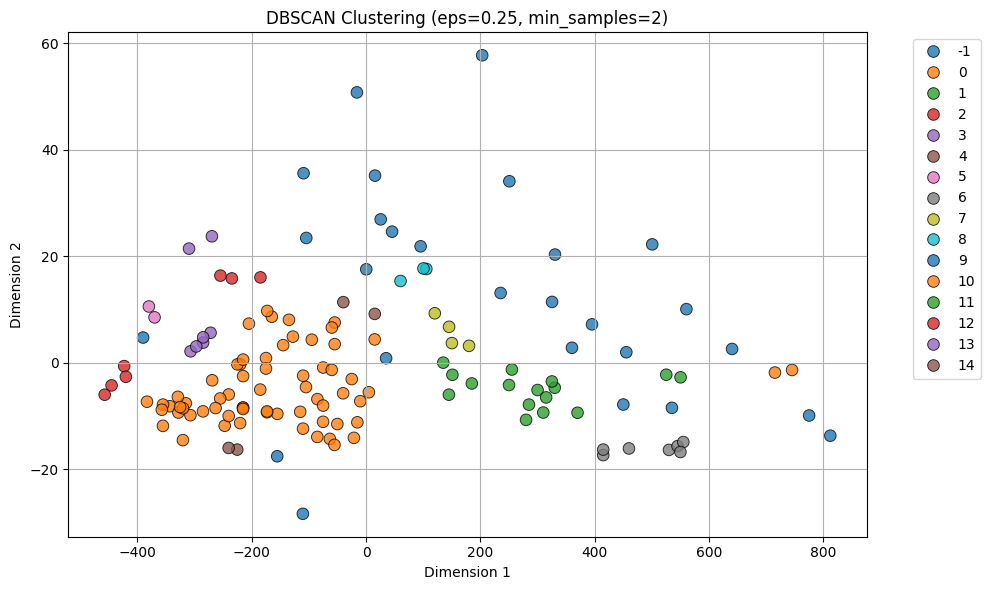

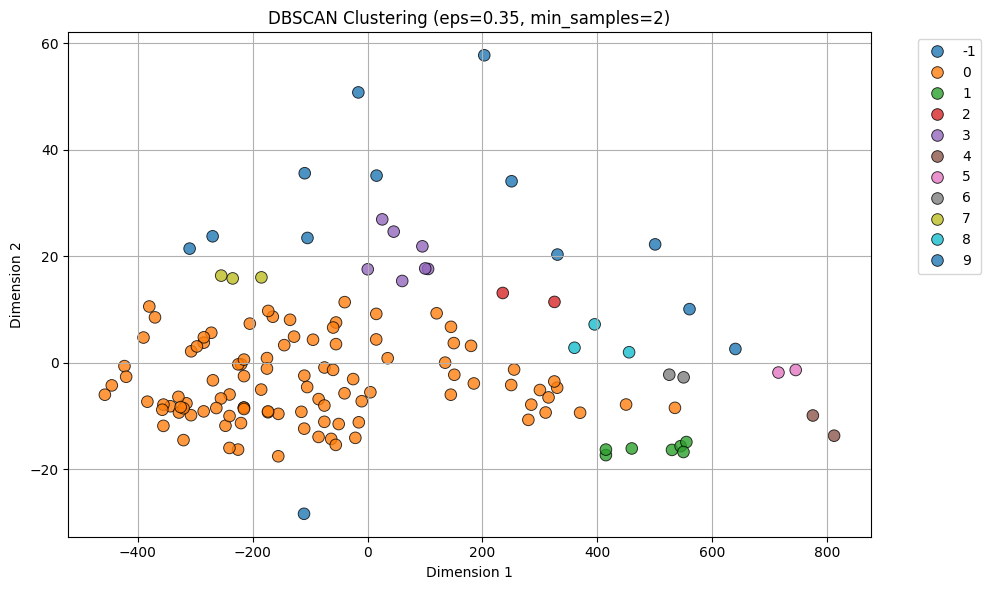

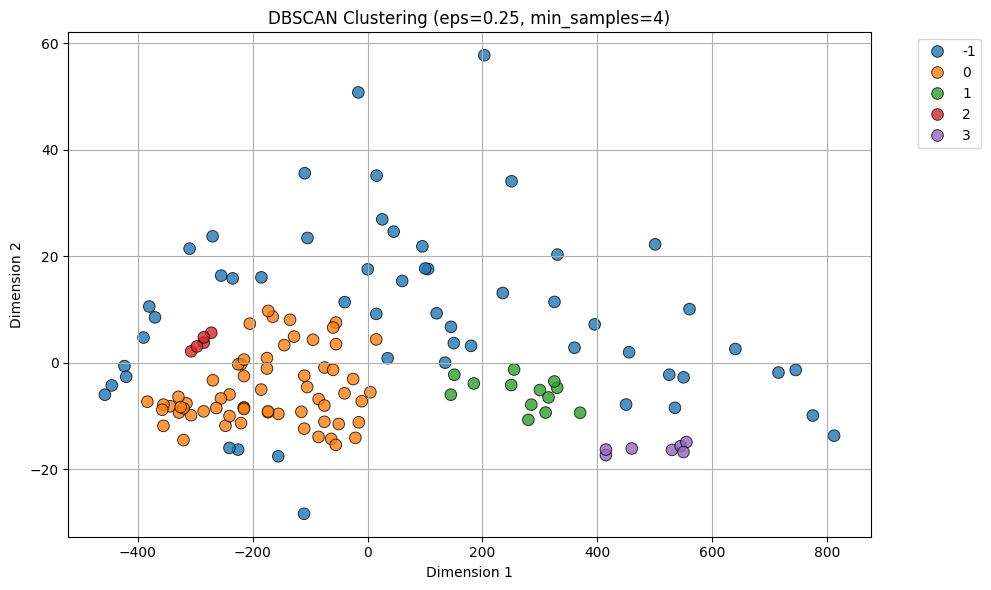

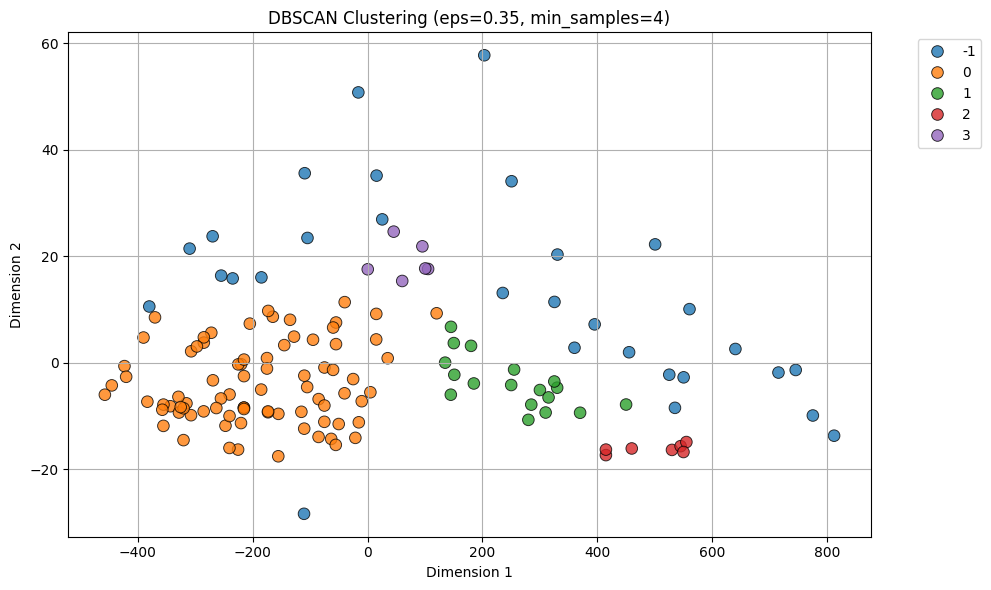

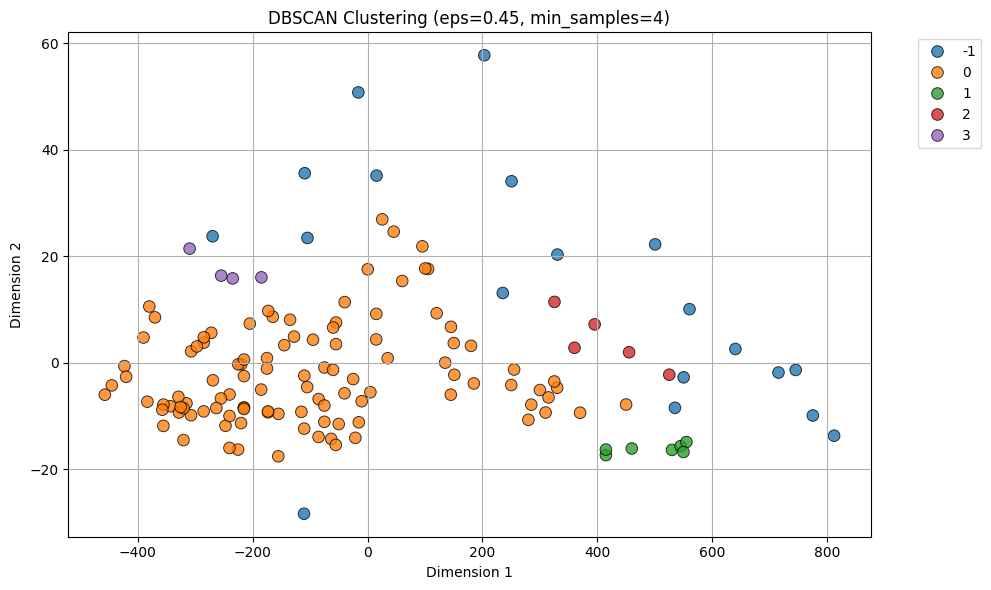

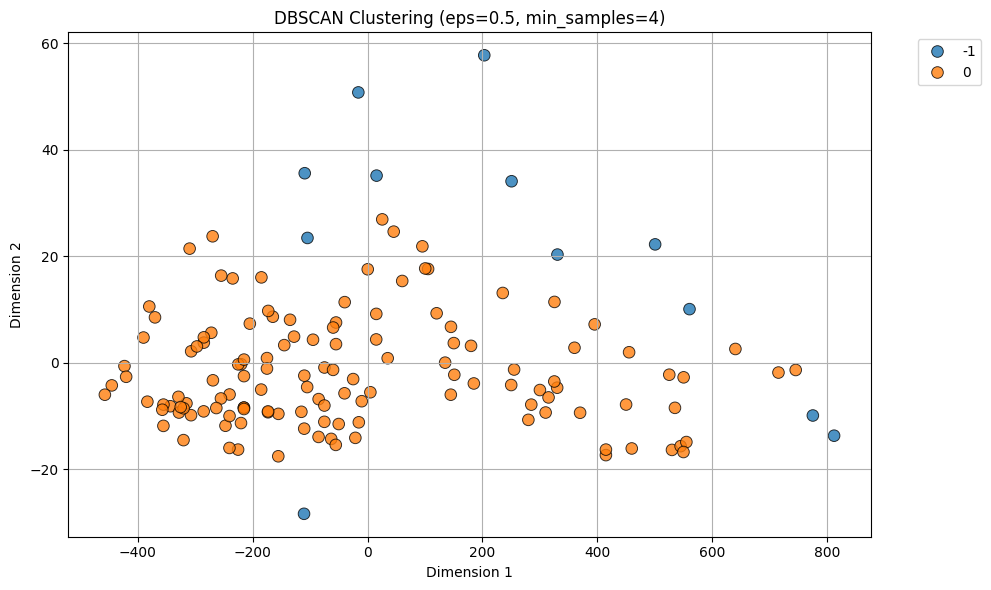

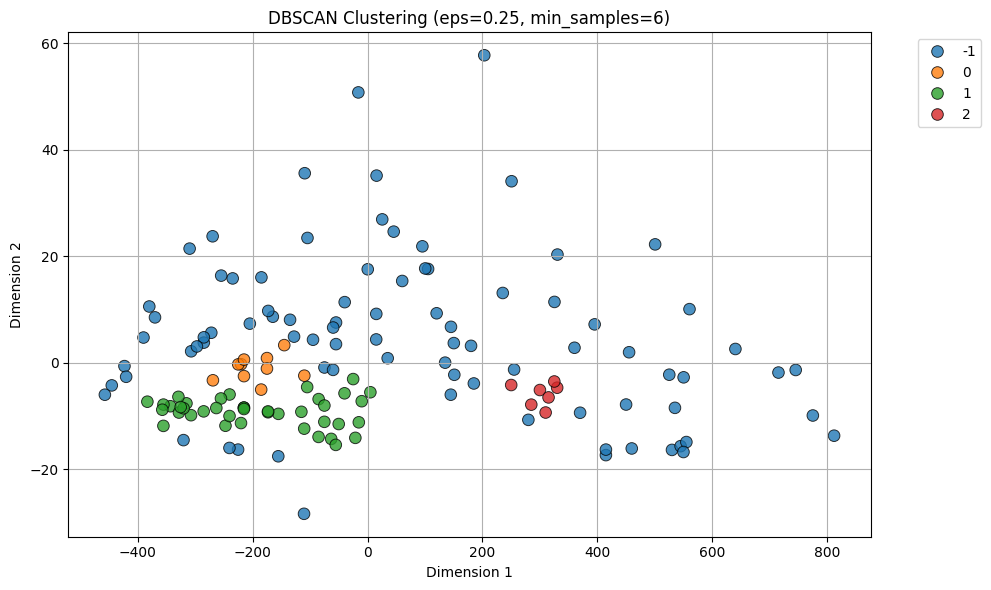

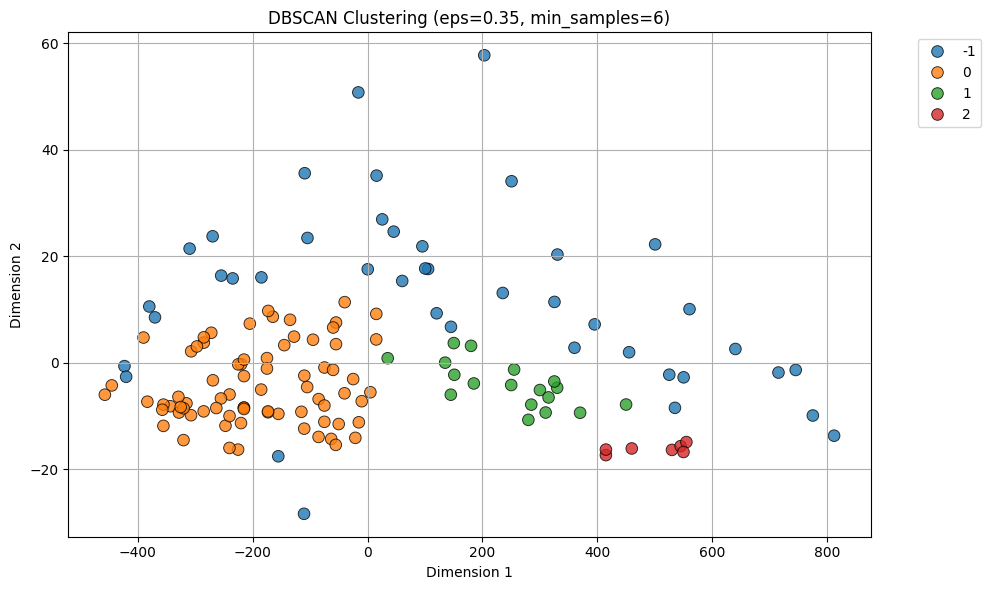

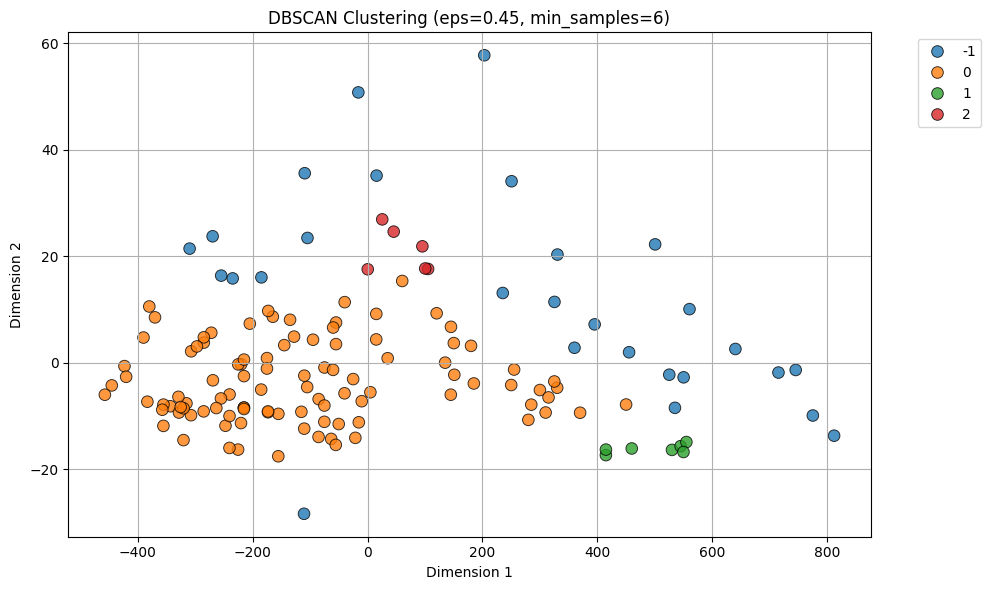

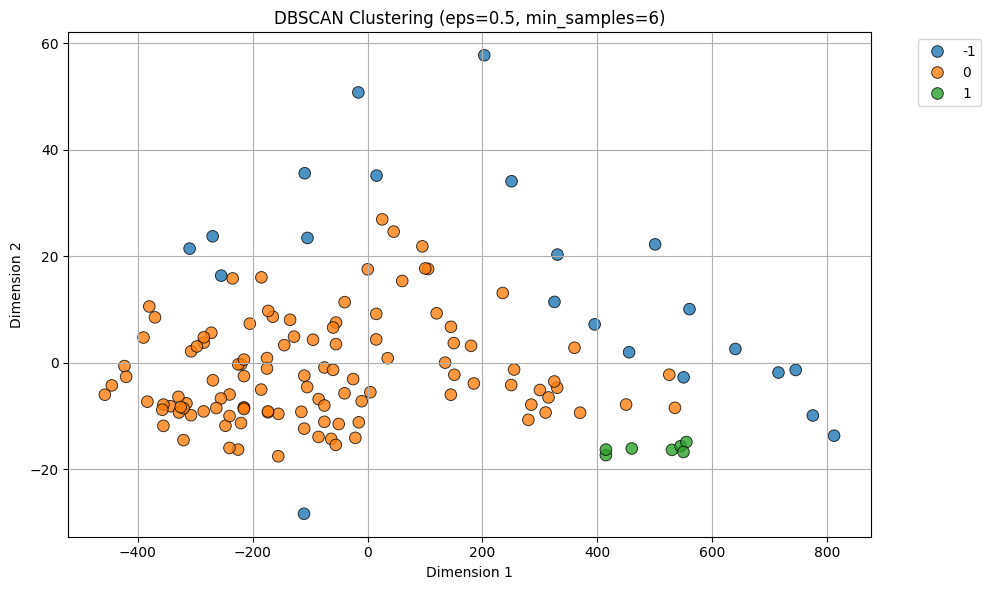

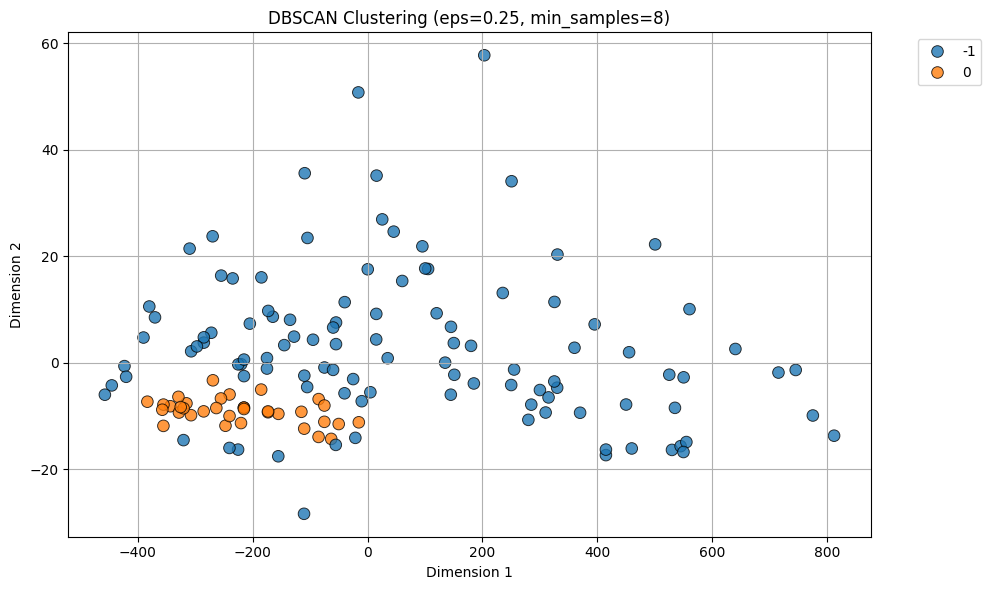

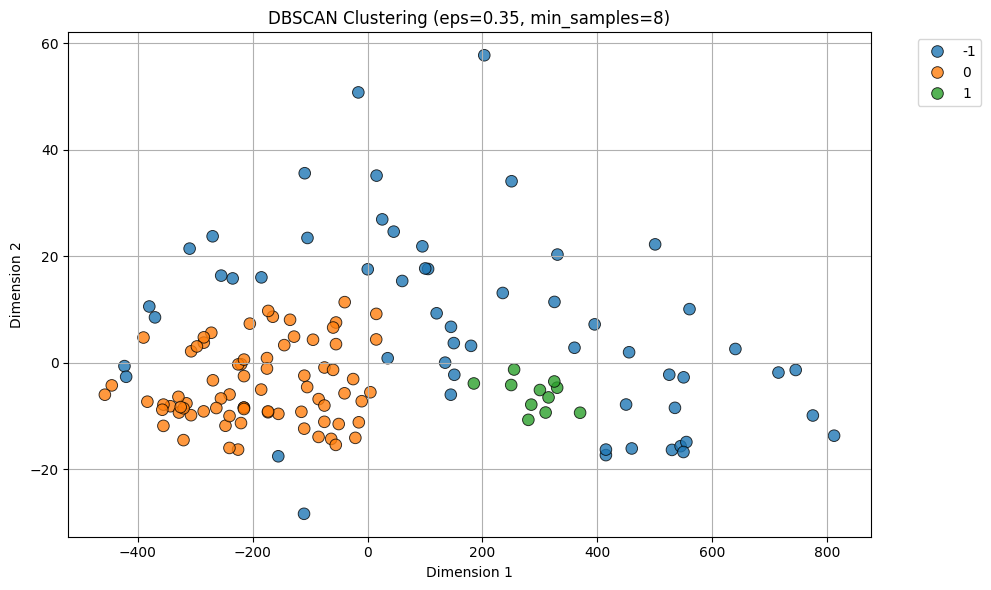

In [7]:
from sklearn.cluster import DBSCAN

def db_plot(eps_var, min_samples_var):

  # Instantiate and fit DBSCAN on scaled features
  dbscan = DBSCAN(eps=eps_var, min_samples=min_samples_var)
  dbscan_labels = dbscan.fit_predict(X_scaled)

  # Add DBSCAN labels to the dataframe
  df['DBSCAN_Cluster'] = dbscan_labels

  # Count clusters and noise points (-1 represents noise points)
  n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
  n_noise_ = list(dbscan_labels).count(-1)

  print(f"Estimated number of clusters: {n_clusters_}")
  print(f"Estimated number of noise points: {n_noise_}")

  # Visualize DBSCAN clustering results
  plt.figure(figsize=(10, 6))
  sns.scatterplot(
      x='Dimension 1',
      y='Dimension 2',
      hue='DBSCAN_Cluster',
      data=df,
      palette='tab10',
      s=70,
      alpha=0.8,
      edgecolor='k',
      legend='full'
  )
  plt.title(f'DBSCAN Clustering (eps={eps_var}, min_samples={min_samples_var})')
  plt.xlabel('Dimension 1')
  plt.ylabel('Dimension 2')
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
  plt.grid(True)
  plt.tight_layout()

  return plt

db_plot(0.25, 2)
db_plot(0.35, 2)

db_plot(0.25, 4)
db_plot(0.35, 4)
db_plot(0.45, 4)
db_plot(0.5, 4)

db_plot(0.25, 6)
db_plot(0.35, 6)
db_plot(0.45, 6)
db_plot(0.5, 6)

db_plot(0.25, 8)
db_plot(0.35, 8)

plt.show()

# Task 6:

 Instructions: **Fit an HDBSCAN model (using min_cluster_size=5 or min_samples=5) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.**

 Here, we will use an HDBSCAN model which creates clusters based on hierarchies. To visualize the HDBSCAN cluster on the 2D PCA projection space, we would use the scaled data set which already projects the data in two principal components. We can see that five clusters are created with some points close to each cluster excluded from the model. This indicates that HDBSCAN model may be creating tighter boundaries for each cluster.

Estimated number of HDBSCAN clusters: 5
Estimated number of HDBSCAN noise points: 64


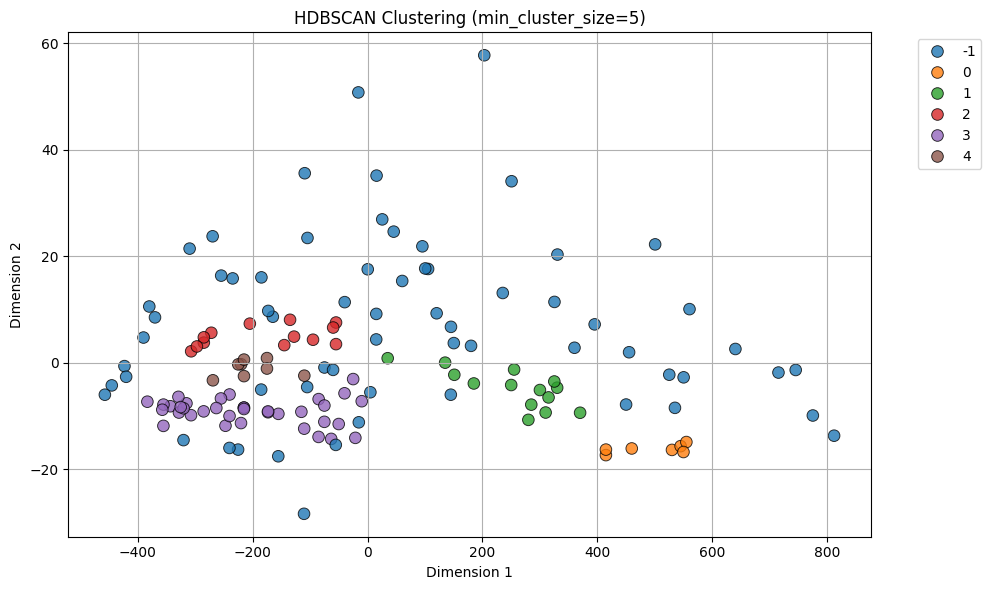

In [8]:
from sklearn.cluster import HDBSCAN

# Instantiate and fit HDBSCAN on scaled features
hdbscan_model = HDBSCAN(min_cluster_size=5)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

# Add HDBSCAN labels to the dataframe
df['HDBSCAN_Cluster'] = hdbscan_labels

# Count clusters and noise points (-1 represents noise points)
n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)

print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")

# Visualize HDBSCAN clustering results
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Dimension 1',
    y='Dimension 2',
    hue='HDBSCAN_Cluster',
    data=df,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    legend='full'
)
plt.title('HDBSCAN Clustering (min_cluster_size=5)')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# **Task 7**

Instructions: **Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.**

As discussed in the [customer_segmentation.ipynb](https://github.com/bforoura/ML26/blob/main/Module8_Unsupervised/customer_segmentation.ipynb) notebook, longer vertical branches in the dendogram indicate that the data can be separated well into distinct clusters. Here, we can see that the dendogram creates two long, blue branches. However, it creates a number of small orange branches which are not as well separated. This could indicate that the dataset may not be well-separated into clusters. This makes sense, because our experiments with the DBSCAN model show that there are a considerable number of points which cannot be well-grouped to a cluster, no matter how much we adjust the hyperparameters of epsilon and minimum samples.

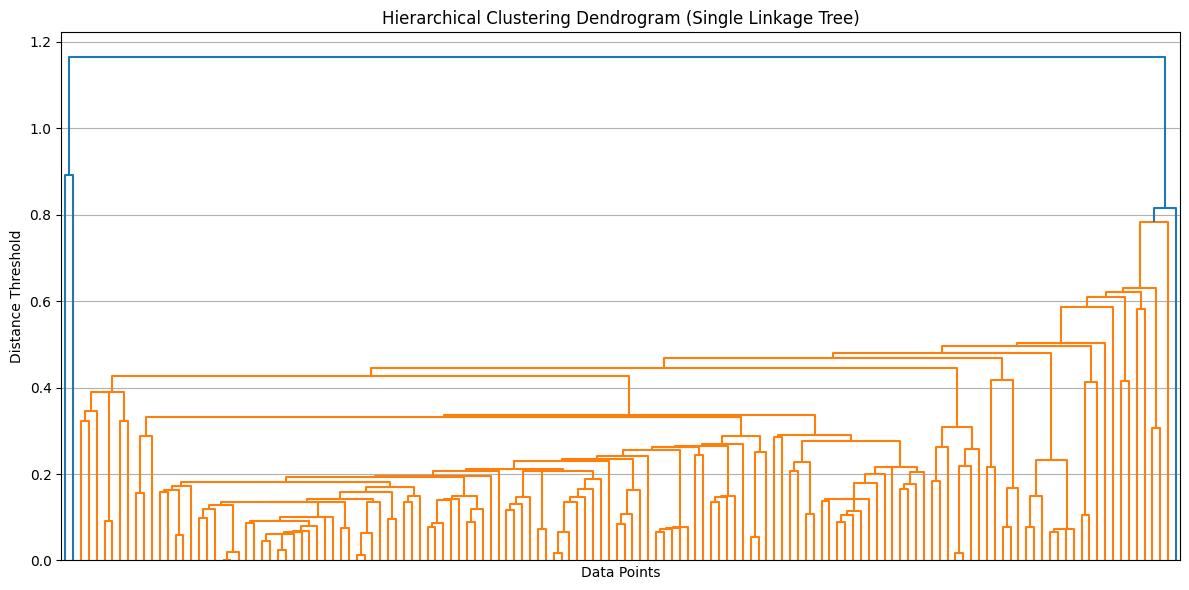

In [9]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np

# Compute the linkage matrix using Ward's method or single linkage on scaled data
# to illustrate the hierarchical tree structure
linked = linkage(X_scaled, method='single')

plt.figure(figsize=(12, 6))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=False,
    no_labels=True
)

plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Data Points')
plt.ylabel('Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

 # Task 8

 Instructions: **Treat the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a Random Forest or Logistic Regression using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). Plot the classification accuracy and Silhouette Scores for all three algorithms.**


 The following displays the dataframe which uses K-Means, DBSCAN, and HDBSCAN as categorical features. We will use these features to predict the true value of the wine cutivars and use a logistic regression to do so.

In [15]:
X_scaled_df = pd.DataFrame(X_scaled, columns=["Dimension 1", "Dimension 2"])
X_scaled_df

,Dimension 1,Dimension 2
0,-0.248692,-0.064028
1,-0.730035,-0.018744
2,-0.249253,-0.820804
3,-0.381948,-0.681087
4,0.945933,-0.581342
...,...,...
137,-1.079030,-0.615289
138,-0.747503,-1.207776
139,2.694943,-1.014014
140,-0.797311,-1.184642


We will test the classification accuracy and silhouette score when the dataset does not have the pseudolabels. We see that the logistic regression model had an accuracy score of 0.69 and a silhouette score of about 0.14.

In [16]:
from sklearn.linear_model import LogisticRegression

# Split data into train and test sets
X_train, X_test, y_train_classifier, y_test_classifier = train_test_split(X_scaled_df, y_train, test_size=0.2, random_state=42)

# extra code – measure the accuracy when we use the whole training set
log_reg_full = LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train, y_train_classifier)
print(f" Accuracy Score {log_reg_full.score(X_test, y_test_classifier)}")
print(f" Silhouette Score {silhouette_score(X_test, y_test_classifier)}")

 Accuracy Score 0.6896551724137931
 Silhouette Score 0.13677715558229178


Then, we will test the classification accuracy and silhouette score when the dataset is labeled with K-Means, DBSCAN, and HDBSCAN labels. We can see that the accuracy score slightly improves but the sihouette score climbs to 0.21. A silhouette score of 0.28 which, as discussed earlier, is the sihouette score for using three clusters.

In [17]:
from sklearn.linear_model import LogisticRegression

# Split data into train and test sets
X_train, X_test, y_train_classifier, y_test_classifier = train_test_split(df, y_train, test_size=0.2, random_state=42)

# extra code – measure the accuracy when we use the whole training set
log_reg_full = LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train, y_train_classifier)
print(f" Accuracy Score {log_reg_full.score(X_test, y_test_classifier)}")
print(f" Silhouette Score {silhouette_score(X_test, y_test_classifier)}")

 Accuracy Score 0.7241379310344828
 Silhouette Score 0.2157347956485757
